# Compare metadata models: Subset data

We compare five ways to predict malignancy from age, sex and anatomical site, the metadata recorded alongside each image. The questions are which model ranks malignant images best and which fields add useful information.

[03_patient_splitting.ipynb](03_patient_splitting.ipynb) supplies shared patient groups, or folds. [04_dummy_logistic_baseline.ipynb](04_dummy_logistic_baseline.ipynb) introduces the two simplest references. Every method here is assessed on patients excluded from its own training.

The saved run favours spline logistic regression, which learns a smooth age relationship: average precision (AP) 0.0484 versus 0.0184 for the dummy. These are development comparisons, before adding images; the reserved test is not used.

For metric definitions, see the [short concept guide](../concepts.md).


**Current reporting priority:** primary unweighted mean outer-fold ROC-AUC, followed by secondary AP, log loss and Brier. Pooled curves support the comparison. Verified versioned baseline diagnostics supply the dummy/logistic predictions; stage 05 uses matching fixed-family version-2 predictions. Original AP-era numerical examples, ablations, age illustrations and exploratory cutoffs below remain clearly historical supporting evidence. No all-development fit is recreated.

## Context and methods

We predict the outcome of each image, while keeping related images from one patient together. For each fold, train on the other four and predict the held-out group. Combining the five groups gives out-of-fold (OOF) predictions: each scored patient was excluded from their model's training.

Preprocessing, converting raw fields into model inputs, is fitted inside training. Validation patients cannot change categories, missing-age replacements or the learned age curve. Exclude diagnosis and benign/malignant descriptions because they reveal the answer, plus identifiers and fold numbers.

Only 1.86% of images are malignant. Average precision (AP), the historical selection measure, rewards placing these rare cases near the top of a score ranking. The results also explain ROC-AUC and probability-error measures. An output in [0,1] is a probability estimate, not proof that its numerical risk is accurate.

Confusion-matrix cutoffs are chosen and assessed from the same OOF labels, so they illustrate exploratory trade-offs. [08_metadata_robustness.ipynb](08_metadata_robustness.ipynb) separates cutoff selection from assessment.


### What each model contributes

| Model | Why include it? | What it learns |
|---|---|---|
| Prevalence dummy | Set a reference for a model with no useful ranking | The malignant-image rate in its training data |
| Standard logistic regression | Start with a simple, readable model | Separate effects for each age category, sex and site |
| Spline logistic regression | Let nearby ages share a smooth pattern | A smooth age curve, plus sex and site effects |
| Random forest | Check whether combinations of fields help | Many decision trees whose predictions are averaged |
| XGBoost | Check a second way to combine decision trees | Trees fitted in sequence to improve earlier predictions |

The spline model uses four knots, which are points where its age curve can bend. This gives age some flexibility without fitting a separate effect to every age category. These settings were chosen as a starting specification; this notebook does not search for the best settings.


## Data

### Set paths and define the modelling tools

The following cells define the models and how we check them. All five methods read the same development data and use the same patient folds, so differences in results reflect the model choices.


In [2]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "src/melanoma_detection").is_dir() and (p / "pyproject.toml").is_file())
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from melanoma_detection.metadata_tuning_v2_reporting import (
    load_tuning, load_baseline_report, render_section, render_baseline_section,
    display_historical_cell, display_historical_source, original_snapshot,
)
plt.rcdefaults()
plt.rcParams['figure.dpi'] = 120
ORIGINAL_EXPORT_DPI = 320
NN_COMPARISON_COLORS = ['#2563EB', '#D97706', '#D97706', '#D97706', '#303030']
report = load_baseline_report(PROJECT_ROOT, 'original', '05', run_id='roc_auc_grid36_v1')
report["export_dpi"] = ORIGINAL_EXPORT_DPI
display(Markdown("**Version-2 saved-results report:** " + report["status"] +
    ". ROC-AUC is primary; AP and probability errors are secondary. No training, final fitting or reserved-test loading starts here."))


C:\Users\thoma\Documents\GitHub\ADS2002-Melanoma\src\melanoma_detection\metadata_tuning_v2_reporting.py:102: DtypeWarning: Columns (0: model) have mixed types. Specify dtype option on import or set low_memory=False.
  frames[name] = pd.read_csv(source, float_precision="round_trip")


**Version-2 saved-results report:** complete. ROC-AUC is primary; AP and probability errors are secondary. No training, final fitting or reserved-test loading starts here.

### Define the shared preprocessing

The standard models turn each category into a yes/no column, a process called one-hot encoding. For example, a site column records whether an image comes from the torso. Age is also treated as a category for these comparisons.

The spline model treats age as a number and learns a smooth curve. It fills a missing age with the training median and scales the curve's numerical features. Each training fold learns its own transformation, using only its training patients.


In [3]:
display_historical_source(PROJECT_ROOT, 'original', '05', 7)

**Historical method reference:** this source explains the original fitting procedure. It is displayed as text and is not executed by this report.

def convert_age_to_numeric(values):
    '''Convert age strings to numbers without changing the source data.'''
    return pd.DataFrame(values).apply(pd.to_numeric, errors="coerce")


def build_preprocessor(features, smooth_age=False):
    '''Create the preprocessing shared by every learned model.'''
    features = list(features)

    if not smooth_age:
        return ColumnTransformer(
            [("categorical", OneHotEncoder(handle_unknown="ignore"), features)],
            remainder="drop",
        )

    transformers = []
    if "age_approx" in features:
        age_steps = Pipeline(
            [
                (
                    "to_numeric",
                    FunctionTransformer(
                        convert_age_to_numeric,
                        feature_names_out="one-to-one",
                    ),
                ),
                ("imputer", SimpleImputer(strategy="median")),
                (
                    "spline",
                    SplineTransformer(
                        n_knots=4,
                        degree=3,
                        knots="quantile",
                        include_bias=False,
                    ),
                ),
                ("scaler", StandardScaler()),
            ]
        )
        transformers.append(("smooth_age", age_steps, ["age_approx"]))

    categorical_features = [
        feature
        for feature in ("sex", "anatom_site_general_challenge")
        if feature in features
    ]
    if categorical_features:
        transformers.append(
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                categorical_features,
            )
        )
    return ColumnTransformer(transformers, remainder="drop")


def logistic_regression():
    '''Use the same simple logistic classifier wherever it is needed.'''
    return LogisticRegression(
        C=1.0, solver="liblinear", max_iter=1_000, random_state=42
    )


def make_metadata_pipeline(classifier, features, smooth_age=False):
    '''Keep preprocessing inside the model so each fold fits it independently.'''
    return Pipeline(
        [
            ("preprocessor", build_preprocessor(features, smooth_age)),
            ("classifier", classifier),
        ]
    )

### Define how we generate held-out predictions

We create a fresh copy of each model for every fold, fit it on four folds and predict the fifth. The helper keeps those predictions in the original image order. The next cell checks that no patient appears in more than one fold.


In [4]:
display_historical_source(PROJECT_ROOT, 'original', '05', 9)

**Historical method reference:** this source explains the original fitting procedure. It is displayed as text and is not executed by this report.

def generate_oof_probabilities(frame, estimator, features):
    '''Train on four folds and predict the held-out fold, five times.'''
    probabilities = np.full(len(frame), np.nan, dtype=float)
    for fold in sorted(frame["fold"].unique()):
        validation_rows = frame["fold"].eq(fold)
        training_rows = ~validation_rows

        fold_model = clone(estimator)
        fold_model.fit(
            frame.loc[training_rows, features],
            frame.loc[training_rows, "target"],
        )
        probabilities[validation_rows] = fold_model.predict_proba(
            frame.loc[validation_rows, features]
        )[:, 1]

    return pd.Series(probabilities, index=frame.index)


def binary_probability_metrics(targets, probabilities):
    '''Return the four metrics reported throughout the notebook.'''
    return {
        "roc_auc": roc_auc_score(targets, probabilities),
        "average_precision": average_precision_score(targets, probabilities),
        "log_loss": log_loss(targets, probabilities, labels=[0, 1]),
        "brier_score": brier_score_loss(targets, probabilities),
    }

### Load and check the development data

Before fitting, check that the required fields are present, the target contains both classes and every patient stays in one fold. The counts below describe the data used for every comparison.


In [5]:
render_baseline_section(report, 'inputs')

,images,patients,malignant_images
fold,,,
0,1370,84,25
1,1372,84,26
2,1381,87,26
3,1371,82,25
4,1370,85,26


Image, patient, fold and target identities match the frozen development records. Baseline probabilities have verified diagnostic provenance.

## Results

### 1. Generate patient-safe out-of-fold predictions

For each fold, the model trains on the other four folds and predicts the held-out fold. Repeating this process gives one validation probability for every image while keeping patients separated.


In [6]:
render_baseline_section(report, 'inputs')

,images,patients,malignant_images
fold,,,
0,1370,84,25
1,1372,84,26
2,1381,87,26
3,1371,82,25
4,1370,85,26


Image, patient, fold and target identities match the frozen development records. Baseline probabilities have verified diagnostic provenance.

### 2. Compare probability performance

The table compares all five models on their combined held-out predictions. ROC-AUC and AP are better when larger; log loss and Brier score are better when smaller. Use primary mean-fold ROC-AUC first, then secondary AP, then check whether the other measures tell a consistent story.


In [7]:
render_baseline_section(report, 'metrics')

,,roc_auc,average_precision,log_loss,brier_score,fold_auc_sd,fold_ap_sd
scope,model,,,,,,
mean_fold,Prevalence dummy,0.50000,0.01865,0.09273,0.01830,0.00000,0.00038
pooled,Prevalence dummy,0.49522,0.01843,0.09273,0.01830,0.00000,0.00038
mean_fold,Standard logistic regression,0.59296,0.05621,0.09134,0.01821,0.07845,0.02376
pooled,Standard logistic regression,0.59445,0.04182,0.09134,0.01821,0.07845,0.02376
mean_fold,Spline logistic regression,0.66289,0.06486,0.08974,0.01814,0.08451,0.02780
pooled,Spline logistic regression,0.64986,0.04837,0.08974,0.01814,0.08451,0.02780
mean_fold,Random forest,0.60502,0.05543,0.09075,0.01815,0.07778,0.02163
pooled,Random forest,0.60603,0.04432,0.09076,0.01816,0.07778,0.02163
mean_fold,XGBoost,0.59686,0.05863,0.09255,0.01822,0.09482,0.02192


### How to read the scores

- Average precision (AP) rewards placing malignant images near the top of the risk ranking. It is not the percentage of images classified correctly. The dummy's 0.0184 provides a reference close to the malignant-image rate.
- ROC-AUC describes how often a malignant image gets a higher score than a benign image. A value of 0.5 is chance-level ranking; 1 is perfect ranking.
- Log loss penalises incorrect probability estimates, especially confident mistakes. Smaller is better.
- Brier score is the average squared difference between the probability and the actual 0/1 label. Smaller is better. With many benign images, a small Brier score alone can hide poor detection of malignant cases.

The spline leads on pooled ROC-AUC and AP. Its AP of 0.0484 is still low, so its higher score does not make metadata a reliable standalone diagnostic method.


### 3. Check how results vary across patient folds

Each row below is a different held-out patient group. Compare the same model across rows before judging its pooled score. Large changes suggest that the result depends on which patients happen to be held out.


In [8]:
render_baseline_section(report, 'fold_metrics')

roc_auc  average_precision  log_loss  \
fold model                                                                
0    Prevalence dummy              0.50000            0.01825   0.09115   
     Standard logistic regression  0.63539            0.04227   0.08977   
     Spline logistic regression    0.79414            0.06608   0.08372   
     Random forest                 0.66126            0.04165   0.08904   
     XGBoost                       0.65642            0.05214   0.08913   
1    Prevalence dummy              0.50000            0.01895   0.09393   
     Standard logistic regression  0.49863            0.04810   0.09470   
     Spline logistic regression    0.57369            0.04671   0.09423   
     Random forest                 0.48043            0.05745   0.09479   
     XGBoost                       0.52787            0.06026   0.09570   
2    Prevalence dummy              0.50000            0.01883   0.09344   
     Standard logistic regression  0.55708            0.03191   0.09380   
     Spline logistic regression    0.65348            0.03864   0.09183   
     Random forest                 0.57854            0.03100   0.09289   
     XGBoost                       0.50128            0.02565   0.09835   
3    Prevalence dummy              0.50000            0.01823   0.09109   
     Standard logistic regression  0.70309            0.06649   0.08461   
     Spline logistic regression    0.68371            0.06251   0.08632   
     Random forest                 0.66502            0.05892   0.08595   
     XGBoost                       0.73001            0.07150   0.08376   
4    Prevalence dummy              0.50000            0.01898   0.09404   
     Standard logistic regression  0.57060            0.09229   0.09380   
     Spline logistic regression    0.60940            0.11033   0.09259   
     Random forest                 0.63985            0.08811   0.09110   
     XGBoost                       0.56874            0.08362   0.09581   

                                   brier_score  
fold model                                      
0    Prevalence dummy                  0.01792  
     Standard logistic regression      0.01807  
     Spline logistic regression        0.01761  
     Random forest                     0.01790  
     XGBoost                           0.01791  
1    Prevalence dummy                  0.01859  
     Standard logistic regression      0.01847  
     Spline logistic regression        0.01867  
     Random forest                     0.01841  
     XGBoost                           0.01839  
2    Prevalence dummy                  0.01847  
     Standard logistic regression      0.01848  
     Spline logistic regression        0.01848  
     Random forest                     0.01851  
     XGBoost                           0.01882  
3    Prevalence dummy                  0.01790  
     Standard logistic regression      0.01752  
     Spline logistic regression        0.01757  
     Random forest                     0.01756  
     XGBoost                           0.01746  
4    Prevalence dummy                  0.01862  
     Standard logistic regression      0.01849  
     Spline logistic regression        0.01836  
     Random forest                     0.01840  
     XGBoost                           0.01851

The spline's AP ranges from 0.0386 to 0.1103 across folds. Different patient groups produce different results, and the spline does not lead every fold. This variation is a reason to check uncertainty in later model comparisons.


### 4. Read the ROC and precision-recall curves

Each row is one model: blue logistic regression, gold spline, olive random forest and orange XGBoost. Curves trace changing cutoffs; axis fractions such as 0.2 mean 20%.

- **Left: ROC.** The horizontal axis is benign images incorrectly flagged (false-positive rate); the vertical axis is malignant images found (recall). Closer to the upper-left is better. The grey diagonal is chance ranking.
- **Right: precision-recall.** Recall is horizontal; precision, the malignant share of flagged images, is vertical. Higher precision at the same recall means fewer false alarms. The grey line marks the 1.86% malignant-image share. The vertical view stops at 30%, excluding the endpoint at recall zero and precision one.

Read both panels: above-chance ranking can coexist with low precision. These curves compare cutoffs without endorsing one.


**Historical supporting section:** its saved pre-migration diagnostic is retained below; it does not select the current final procedure.

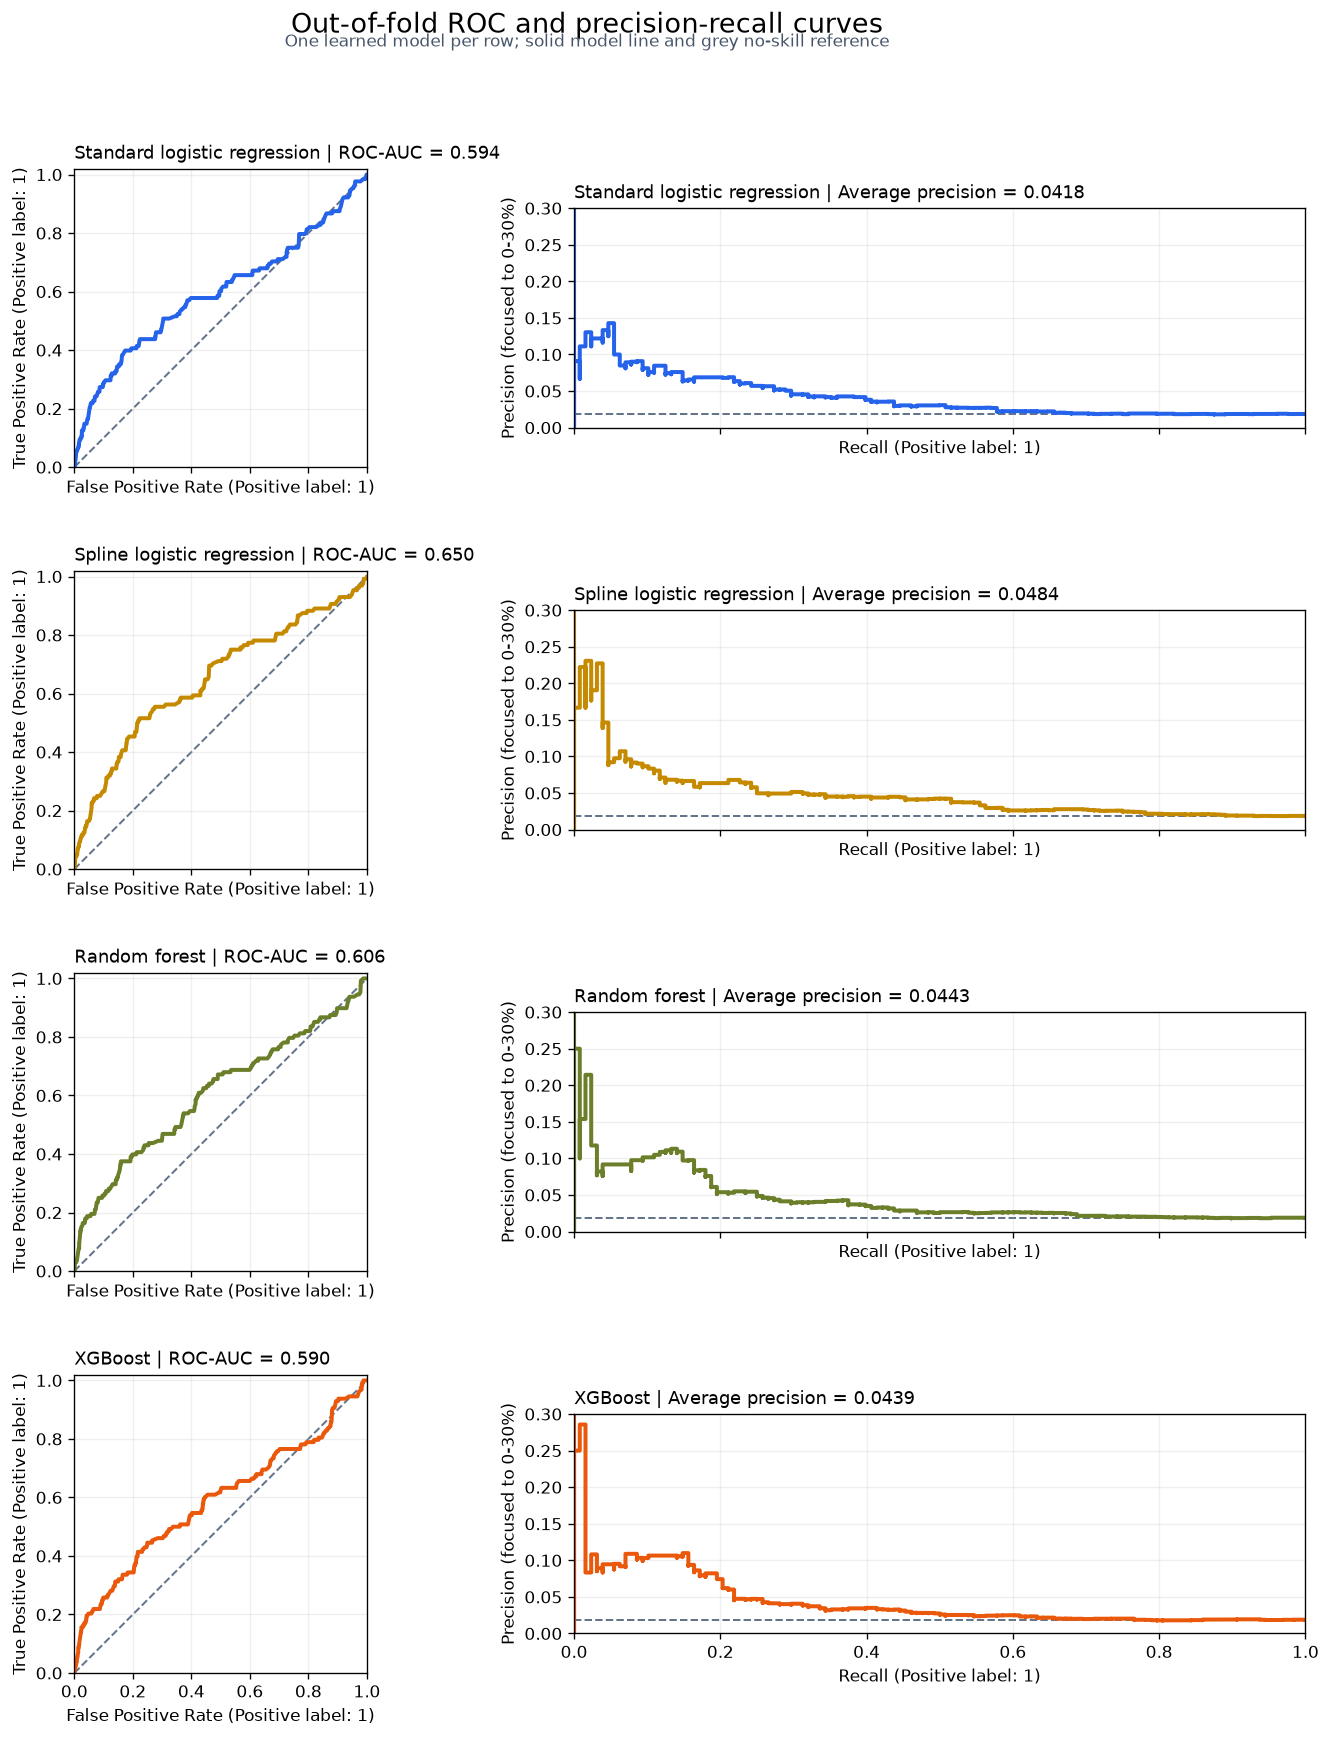

In [9]:
render_baseline_section(report, 'curves')

### 5. Remove fields to see where the signal comes from

We refit the same spline-logistic model using different combinations of age, sex and site. This is called feature ablation. Keeping the model and patient folds fixed helps us see what each field adds.

In the chart, the vertical axis lists the field combinations and the horizontal axis is held-out AP. Longer blue bars mean better ranking of malignant images. The dashed vertical line is the dummy reference; the printed values give the exact scores. Compare age alone with age plus site, then compare that with all three fields. There are no uncertainty bars here, so tiny differences should not be read as established gains.


**Historical supporting section:** its saved pre-migration diagnostic is retained below; it does not select the current final procedure.

**Historical supporting diagnostic:** saved output of pre-migration `notebooks/Subset/05_metadata_models.ipynb`, cell 23. Its AP-era interpretation and fitted age illustration are preserved; no model is fitted to recreate it.

,Features,roc_auc,average_precision,Average precision gain vs dummy,log_loss,brier_score
Feature set,,,,,,
Sex only,sex,0.5227,0.0196,0.0012,0.0926,0.0183
Age only,age_approx,0.6304,0.0410,0.0226,0.0902,0.0182
Site only,anatom_site_general_challenge,0.5476,0.0264,0.0080,0.0916,0.0182
Sex + age,"sex, age_approx",0.6205,0.0402,0.0217,0.0905,0.0182
Sex + site,"sex, anatom_site_general_challenge",0.5798,0.0292,0.0108,0.0915,0.0182
Age + site,"age_approx, anatom_site_general_challenge",0.6553,0.0479,0.0295,0.0895,0.0181
All features,"sex, age_approx, anatom_site_general_challenge",0.6499,0.0484,0.0299,0.0897,0.0181


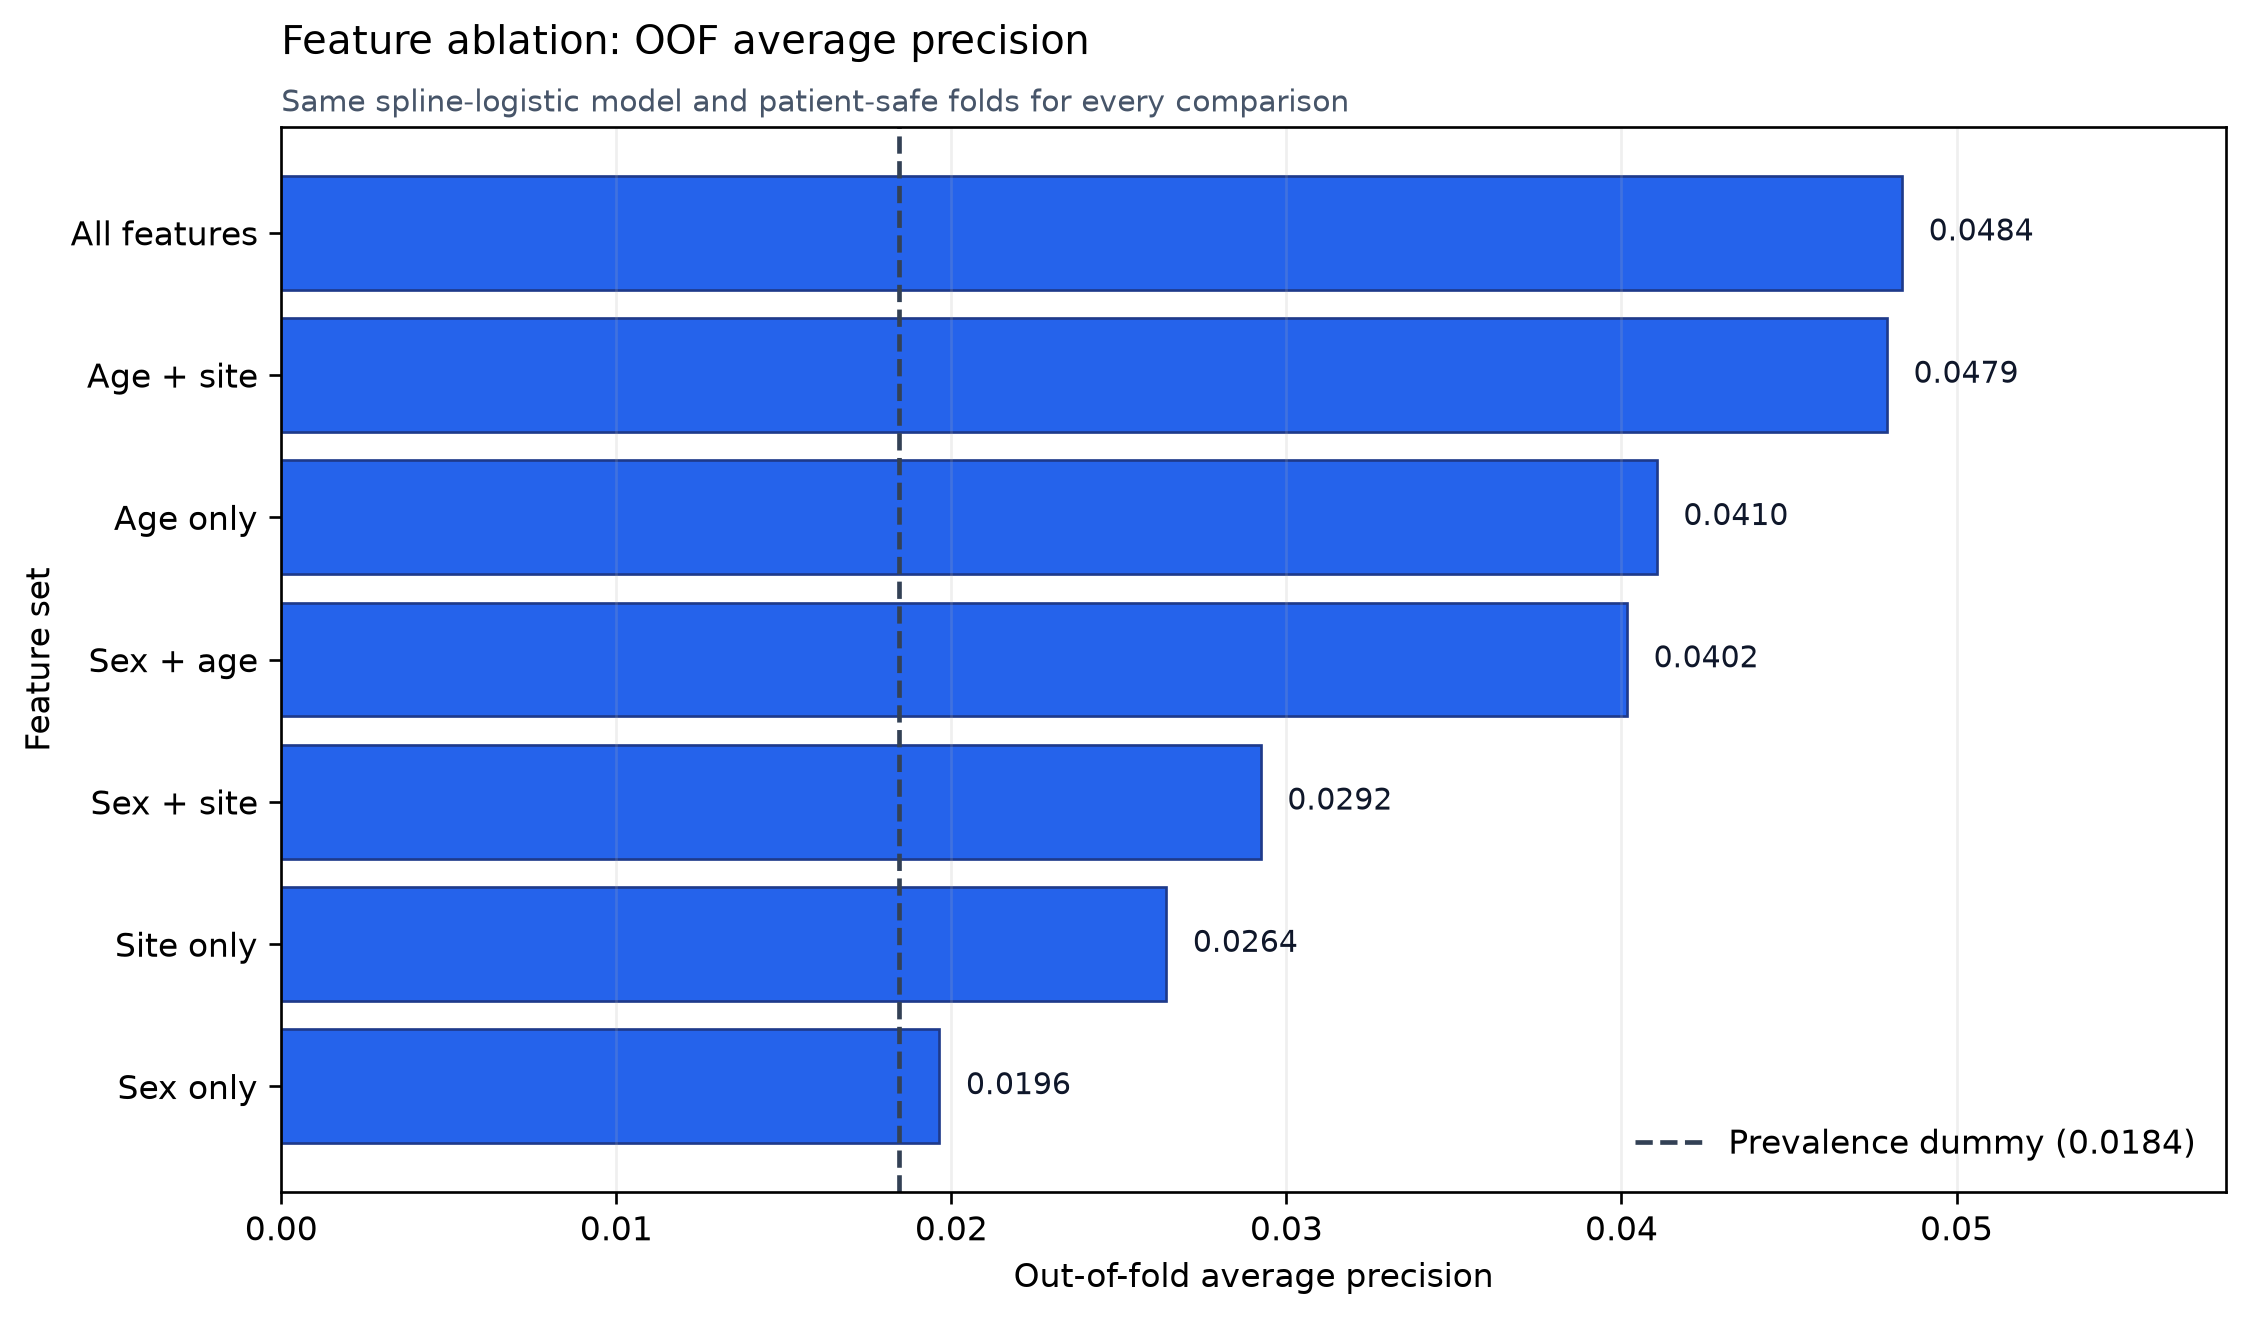

In [10]:
display_historical_cell(PROJECT_ROOT, 'original', '05', 23)

Age gives the strongest individual signal, with AP 0.0410. Site alone reaches 0.0264, and adding it to age raises AP to 0.0479. Sex alone is close to the dummy, at 0.0196. Adding sex to age and site raises AP slightly to 0.0484 while lowering ROC-AUC from 0.655 to 0.650.

Age and site account for most of the useful signal in this run. The small change from adding sex needs an uncertainty check before we treat it as a dependable improvement. These comparisons describe predictive usefulness, not the causes of melanoma.


### 6. Read the fitted age relationship

This descriptive view fits the spline on all development images. For each age, assign that age to all records and average the model scores over their recorded sex and site. The performance scores above still use held-out predictions.

The horizontal axis is approximate age; the vertical axis is percentage. The gold line is the average model score; blue-outlined points are observed malignant percentages. Larger points mean more images. Compare the broad pattern: small groups can fluctuate sharply. Neither series has uncertainty intervals, and the fitted line does not establish calibrated individual risks.


**Historical supporting diagnostic:** saved output of pre-migration `notebooks/Subset/05_metadata_models.ipynb`, cell 26. Its AP-era interpretation and fitted age illustration are preserved; no model is fitted to recreate it.

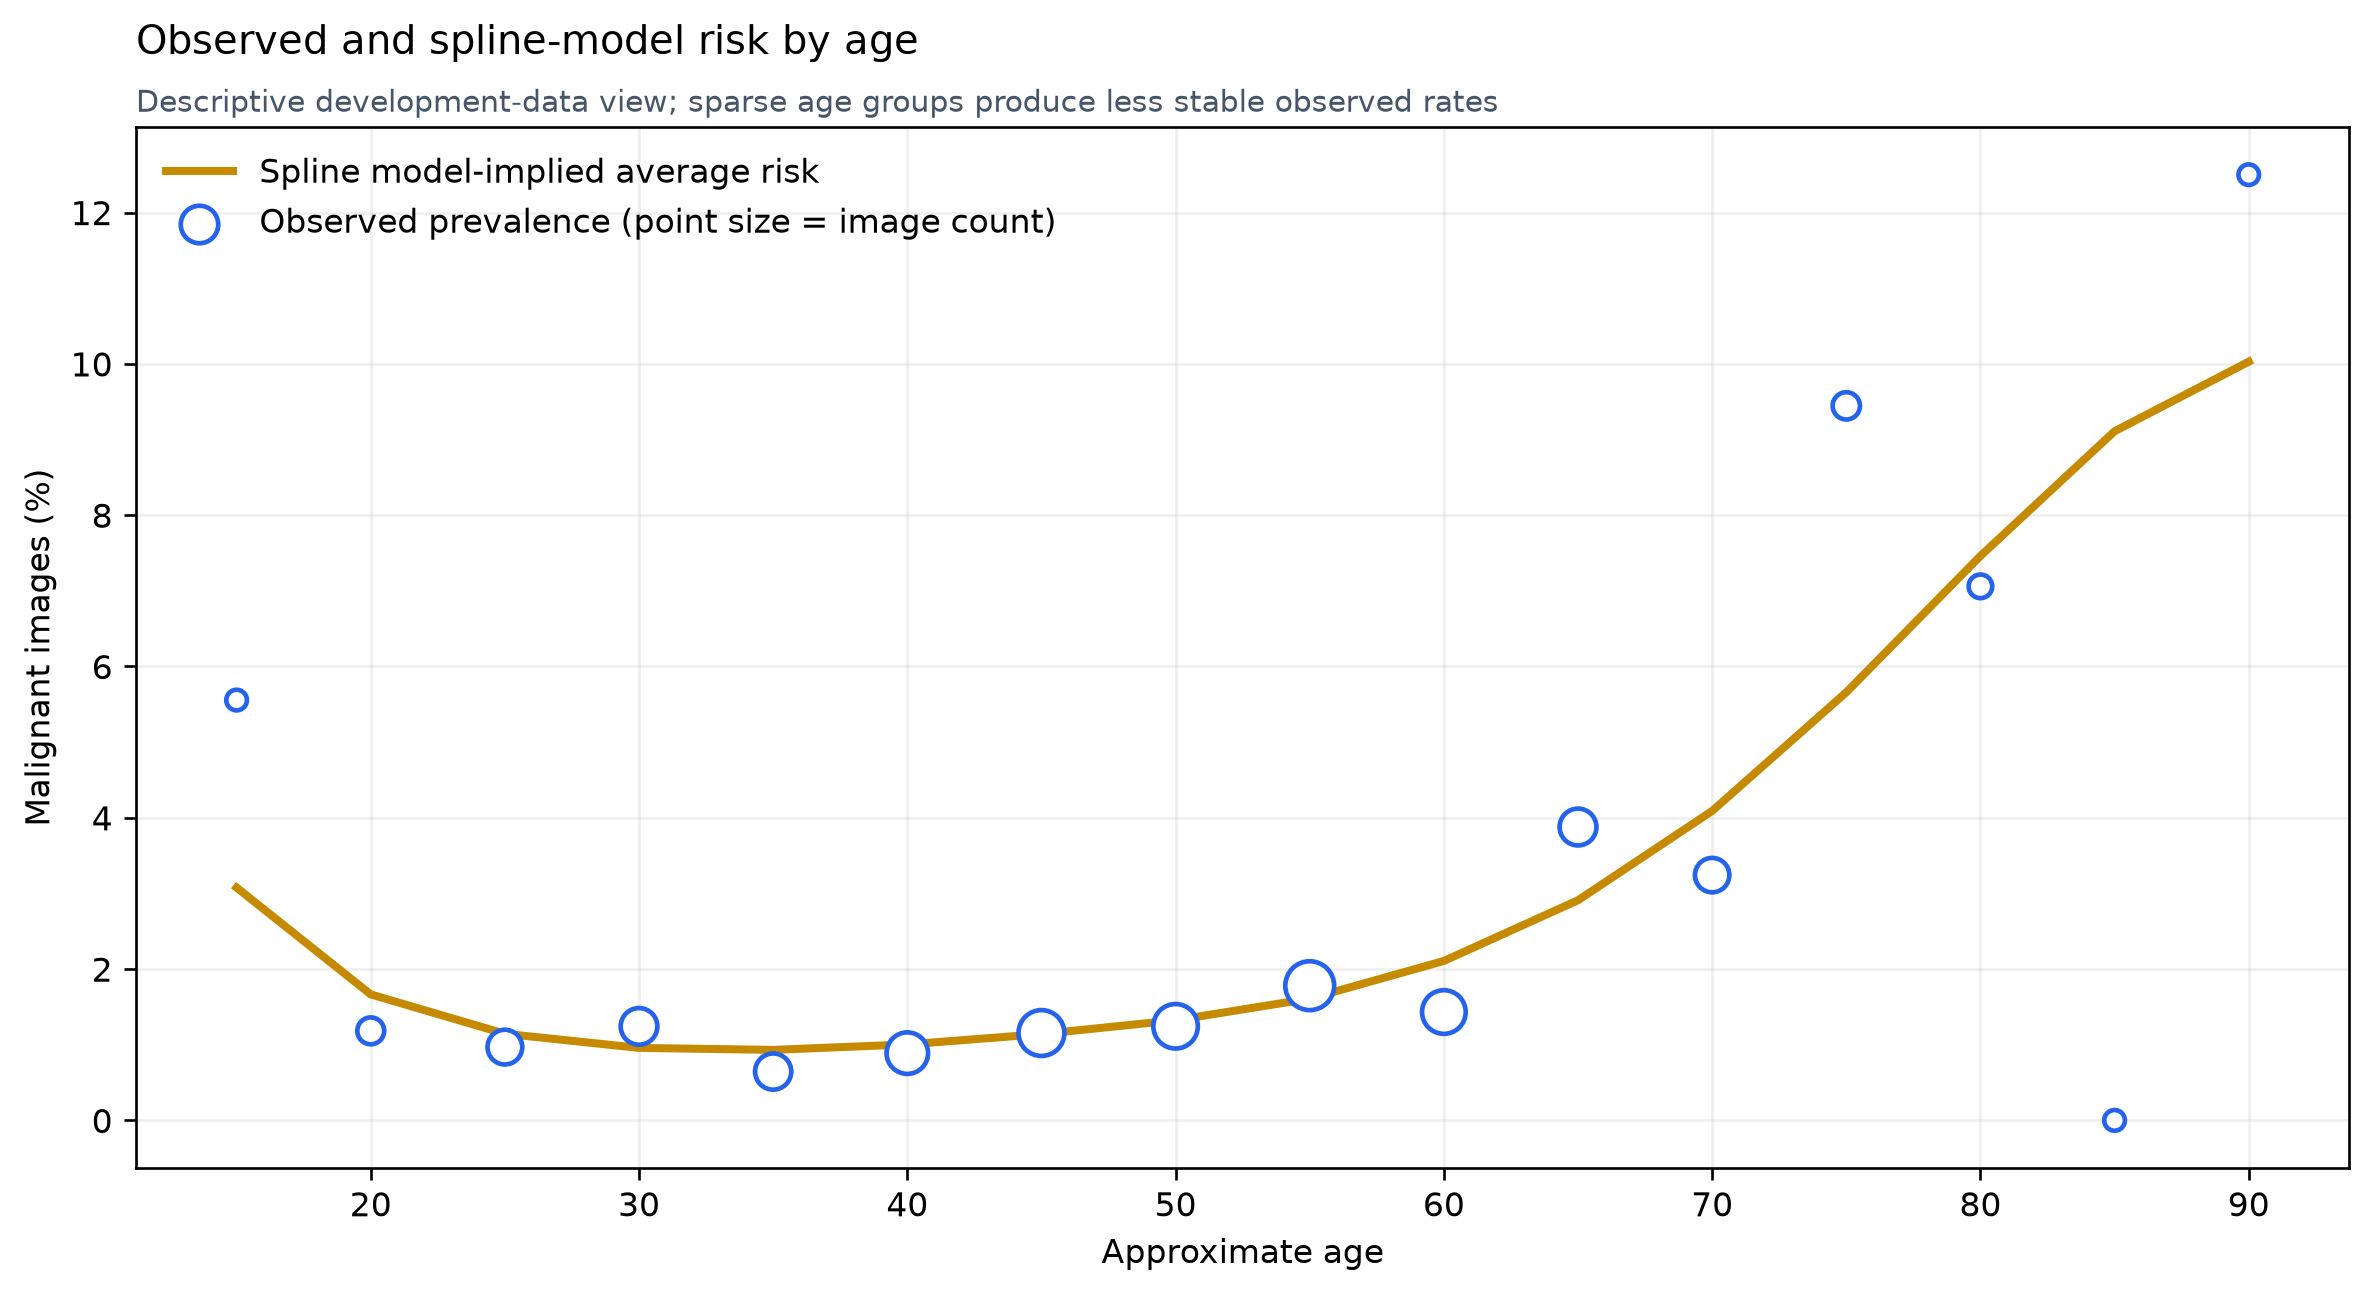

,age,images,malignant_images,Observed prevalence (%),Model-implied average risk (%)
0,15,18,1,5.56,3.08
1,20,169,2,1.18,1.67
2,25,413,4,0.97,1.14
3,30,483,6,1.24,0.96
4,35,465,3,0.65,0.93
5,40,675,6,0.89,1.00
6,45,866,10,1.15,1.14
7,50,804,10,1.24,1.32
8,55,1011,18,1.78,1.61
9,60,768,11,1.43,2.11


In [11]:
display_historical_cell(PROJECT_ROOT, 'original', '05', 26)

The fitted curve generally rises at older ages. The observed rates fluctuate, particularly where few images are available: age 90 has only 16 images, for example. The curve smooths those jumps, but fitting a smooth line does not remove uncertainty. This is an association in the development data, not evidence that age causes an individual lesion to be malignant.


### 7. Describe the observed rates by sex and site

The next table counts malignant images within each category. Read the image count and malignant count beside the percentage. A high percentage based on a handful of cases provides much weaker evidence than the same percentage based on many cases.


In [12]:
display_historical_cell(PROJECT_ROOT, 'original', '05', 29)

**Historical supporting diagnostic:** saved output of pre-migration `notebooks/Subset/05_metadata_models.ipynb`, cell 29. Its AP-era interpretation and fitted age illustration are preserved; no model is fitted to recreate it.

,Feature,Category,images,malignant_images,Prevalence (%)
0,Sex,male,3311,75,2.27
1,Sex,female,3553,53,1.49
2,Anatomical site,oral/genital,33,3,9.09
3,Anatomical site,head/neck,409,21,5.13
4,Anatomical site,upper extremity,1066,23,2.16
5,Anatomical site,torso,3440,54,1.57
6,Anatomical site,lower extremity,1650,25,1.52
7,Anatomical site,Unknown,196,2,1.02
8,Anatomical site,palms/soles,70,0,0.00


These are unadjusted descriptive rates. Categories with few images or malignant cases, such as oral/genital and palms/soles, can show extreme percentages by chance and should not be ranked as if their estimates were equally reliable.


### 8. Choose exploratory cutoffs for confusion matrices

A cutoff turns a probability into a decision: images at or above it are flagged. At 0.50, every model in this run leaves every image unflagged. The probabilities are mostly small because malignant images are rare.

For each learned model, we try every distinct predicted probability, plus 0 and 1. At each candidate cutoff, we calculate recall and specificity, the fraction of benign images left unflagged. We choose the cutoff with the largest balanced accuracy, the average of recall and specificity. If candidates tie, we choose the one closest to 0.50. The dummy stays at 0.50 because it has no useful ranking within a fold.

The same OOF labels choose the cutoffs and assess their decisions, so this is an exploratory illustration. The training-only selection in notebook 08 provides a better check of a complete cutoff procedure.


**Historical supporting section:** its saved pre-migration diagnostic is retained below; it does not select the current final procedure.

In [13]:
display_historical_cell(PROJECT_ROOT, 'original', '05', 32)

**Historical supporting diagnostic:** saved output of pre-migration `notebooks/Subset/05_metadata_models.ipynb`, cell 32. Its AP-era interpretation and fitted age illustration are preserved; no model is fitted to recreate it.

Default 0.50 threshold results:



,Threshold,TN,FP,FN,TP
Model,,,,,
Prevalence dummy,0.5,6736,0,128,0
Standard logistic regression,0.5,6736,0,128,0
Spline logistic regression,0.5,6736,0,128,0
Random forest,0.5,6736,0,128,0
XGBoost,0.5,6736,0,128,0


,Threshold,Threshold type,Balanced accuracy
Model,,,
Prevalence dummy,0.5000,Fixed,0.5000
Standard logistic regression,0.0273,Maximum balanced accuracy,0.6124
Spline logistic regression,0.0225,Maximum balanced accuracy,0.6466
Random forest,0.0258,Maximum balanced accuracy,0.6079
XGBoost,0.0234,Maximum balanced accuracy,0.5985


### 9. Read the confusion matrices

Each panel shows the counts produced by its model's chosen cutoff. Rows are the actual class and columns are the predicted class. The upper-left cell is a benign image left unflagged (TN); the upper-right is a benign image flagged by mistake (FP). The lower-left is a missed malignant image (FN); the lower-right is a malignant image found (TP).

The percentages use the actual class as their denominator. The top row adds to 100% of benign images and the bottom row adds to 100% of malignant images. Compare the bottom-right percentage with the top-right percentage to see the detection/false-alarm trade-off. Darker blue means more images, using one shared count scale across panels. Read the numbers as well as the shading, because benign images greatly outnumber malignant ones.

These matrices make the practical cost of a cutoff visible. They do not show final-test performance or establish a clinical decision rule.


**Historical supporting section:** its saved pre-migration diagnostic is retained below; it does not select the current final procedure.

**Historical supporting diagnostic:** saved output of pre-migration `notebooks/Subset/05_metadata_models.ipynb`, cell 34. Its AP-era interpretation and fitted age illustration are preserved; no model is fitted to recreate it.

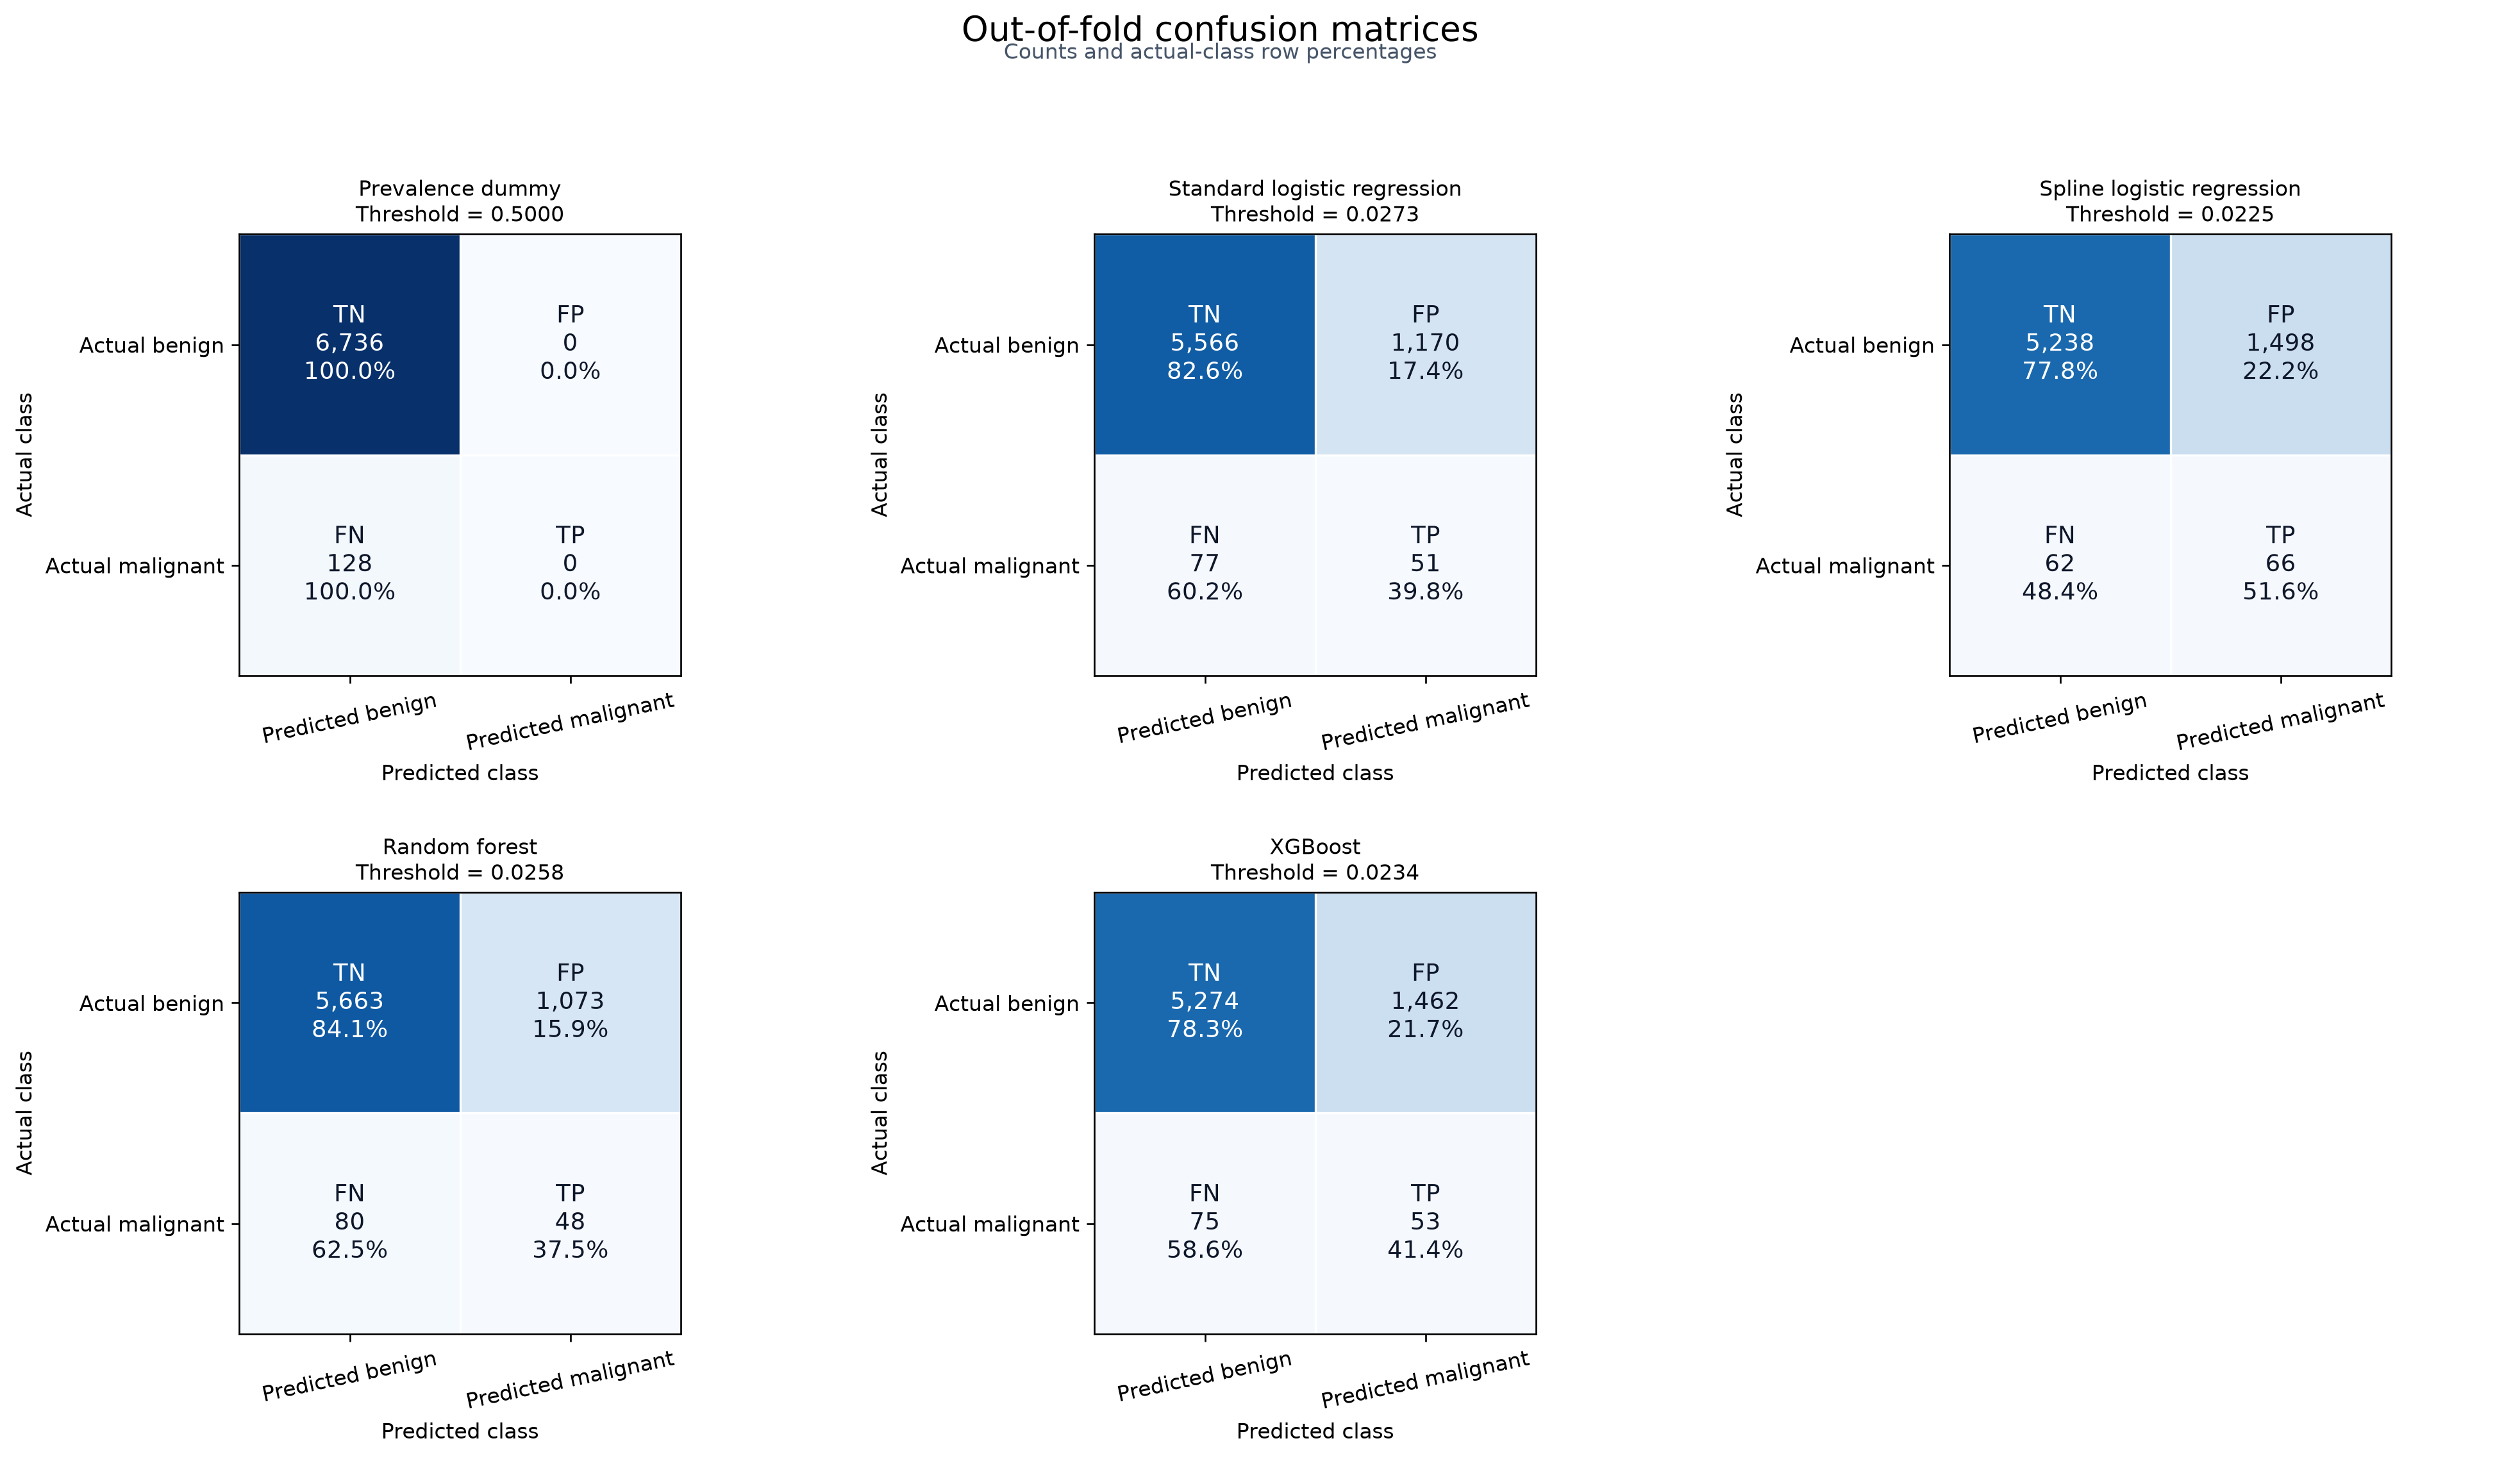

,Threshold,TN,TN % of actual benign,FP,FP % of actual benign,FN,FN % of actual malignant,TP,TP % of actual malignant,Precision among predicted malignant (%)
Model,,,,,,,,,,
Prevalence dummy,0.5000,6736,100.0,0,0.0,128,100.0,0,0.0,0.0
Standard logistic regression,0.0273,5566,82.6,1170,17.4,77,60.2,51,39.8,4.2
Spline logistic regression,0.0225,5238,77.8,1498,22.2,62,48.4,66,51.6,4.2
Random forest,0.0258,5663,84.1,1073,15.9,80,62.5,48,37.5,4.3
XGBoost,0.0234,5274,78.3,1462,21.7,75,58.6,53,41.4,3.5


In [14]:
display_historical_cell(PROJECT_ROOT, 'original', '05', 34)

## Where this comparison leads

[04_dummy_logistic_baseline.ipynb](04_dummy_logistic_baseline.ipynb) gives a shorter walkthrough of the two basic references. [06_metadata_neural_network.ipynb](06_metadata_neural_network.ipynb) checks whether a small neural network helps, and [07_metadata_tuning.ipynb](07_metadata_tuning.ipynb) checks changes to the model settings.

[08_metadata_robustness.ipynb](08_metadata_robustness.ipynb) then adds patient-based uncertainty intervals, training-only cutoff selection, calibration plots and subgroup checks. The [methodology guide](../../docs/metadata_methodology.md) explains why those steps matter.


**Historical supporting section:** its saved pre-migration diagnostic is retained below; it does not select the current final procedure.

## Limitations

These folds have been used to compare several models and field combinations. Choosing the most promising result after seeing all of them can make that winner look better than it will on new patients. Patient separation prevents direct training leakage, but it cannot remove the effect of repeated development choices.

There are only 128 malignant images from 88 patients, and some ages and sites contain very few cases. This notebook does not provide confidence intervals for the model or field comparisons. Its age plot and category rates are descriptive associations; they cannot explain causation. The cutoffs are chosen and assessed on the same predictions, and the plots do not establish calibrated probabilities or clinical safety.

Metadata contains no lesion appearance. These results do not establish performance at another hospital or on the reserved test set, which has not been used to evaluate these models.


**Historical supporting section:** its saved pre-migration diagnostic is retained below; it does not select the current final procedure.

## Summary

The spline logistic model is the strongest of these five fixed methods on pooled AP (0.0484) and ROC-AUC (0.6499). Age supplies most of the individual metadata signal, and site adds information. Sex adds only a small change beyond those fields.

Retain the fixed spline as the primary metadata model and the dummy as the reference. Keep the standard logistic and tree results as comparisons. At the spline's exploratory cutoff of 0.0225, it finds 66 of 128 malignant images (51.6%) while incorrectly flagging 1,498 of 6,736 benign images (22.2%). That trade-off shows why a higher ranking score alone is insufficient.

Next, check the network and tuning experiments, then use notebook 08 to assess uncertainty, probability calibration and a cutoff selected from training patients. Freeze the complete method before evaluating the reserved test set once.


**Historical supporting section:** its saved pre-migration diagnostic is retained below; it does not select the current final procedure.

### Current ROC-AUC-first recap

Read the mean-fold ROC-AUC comparison first. Keep rare-positive AP, probability error, patient support and the historical diagnostics alongside it. The comparison supplies development evidence rather than a new final model or test result.

In [15]:
render_baseline_section(report, 'summary')

**Primary mean-fold ROC-AUC:** Prevalence dummy 0.5000; Standard logistic regression 0.5930; Spline logistic regression 0.6629; Random forest 0.6050; XGBoost 0.5969. AP, log loss and Brier remain secondary; pooled curves support interpretation. These are patient-held-out development comparisons. Historical ablations, cutoffs and age illustrations are separately labelled supporting diagnostics. A point ordering does not automatically choose a final model; no all-development fit or reserved-test evaluation is performed.